### SEM 8 MAJOR PROJECT
# **MOVIE RECOMMENDATION SYSTEM USING COLLABORATIVE FILTERING**

There are 3 ways to create a Movie Recommendation Model, namely:

1. Item-Based / Content-Based Method
2. User-Based Method
3. Collaborative Filtering


1. **ITEM-BASED / CONTENT-BASED METHOD:** This filtering approach uses a series of discrete characteristics of an item or a movie in order to recommend additional items with similar properties. It finds similar movies using a movie's attributes like movie ID, its rating, its genre, etc.

2. **USER-BASED METHOD:** This filtering approach uses a series of discrete characteristics of a user in order to recommend additional items with similar properties. User-Based Filtering Methods are totally based on the user's past preferences. It finds similar movies using a user's past preferences. It finds similar movies using a user's attributes like user ID, a user's age, how many movies has a user watched, what rating he has given to a movie, etc.

3. **COLLABORATIVE FILTERING:** This approach finds similar movies using a movie's attributes and a user's information. It builds a model from the user's past behavior i.e. items purchased or searched by the user as well as similar decisions made by the other users. This model is then used to predict items or ratings for items that users may have an interest in. Since this approach makes use of both the Item-Based Approach and the User-Based Approach, this is why it is known as Collaborative Filtering.

## **IMPORTING THE DATASET**

First we need to download a sample movies dataset from the web and extract the README.txt file which contains the detailed descriptions of the data files used in the project.

In [ ]:
import pandas as pd                # It is used for data manipulation and analysis. It offers data structures and operations for manipulating numerical tables
                                   # and time series.
import numpy as np                 # It is a Python Package which provides fast mathematical operations over arrays.
import seaborn as sns              # It is a library used for making statistical graphics in Python. Seaborn helps explore and understand the data.
import matplotlib.pyplot as plt    # Matplotlib is a Python package/library used for creating 2D graphs and plots.
                                   # pyplot is a module in Matplotlib which supports a very wide variety of graphs and plots namely - histogram, bar charts,
                                   # power spectra, error charts, etc.

Then we need to import the CSV file from our local drive into our working environment to get the data.

Then we need to import the u.data data file into a pandas dataframe to read the movie ratings. And create a dataframe 'ratings'.

In [ ]:
# Reading the data of movie ratings

ratings = pd.read_csv('ml-100k/u.data', sep='\t',                 # The data in u.data data file is tab separated.
                     header=None,                                 # Header row is not to be read.
                     names=['user_id', 'movie_id', 'ratings'],    # Passing names for columns since column names are not given in the ratings data.
                     usecols=[0, 1, 2])                           # Passing columns which are supposal graphics in Python. Seaborn helps explore and understand the data.

In [ ]:
ratings.head()    # head() is used to display the data of top 5 rows. 

,user_id,movie_id,ratings
0,196,242,3
1,186,302,3
2,22,377,1
3,244,51,2
4,166,346,1


In [ ]:
ratings.user_id.unique().size    # Finding the total count of unique user ID(s)

943

In [ ]:
ratings.movie_id.unique().size    # Finding the total count of unique movies

1682

In [ ]:
ratings.ratings.mean()    # Finding the average rating of all the movies

3.52986

## **DATA PRE-PROCESSING & CALCULATION OF ATTRIBUTE PERCENTAGE OF THE DATA**

In [ ]:
cols = "movie id | movie title | release date | video release date | IMDb URL | \
unknown | Action | Adventure | Animation | Children's | Comedy | Crime | \
Documentary | Drama | Fantasy | Film-Noir | Horror | Musical | Mystery | \
Romance | Sci-Fi | Thriller | War | Western"
cols = cols.split(' | ')    # Separating columns by pipe separation

In [ ]:
movie_title = pd.read_csv('ml-100k/u.item', sep='|',           # Creating a new pandas dataframe named 'movie_title' to store the names of all the movies inside it.
                         encoding='latin', header=None,
                         names=['movie id', 'movie title'],    # Passing only 2 columns
                         usecols=[0, 1],                       # Using only columns 0 and 1, and dropping rest of the columns
                         index_col='movie id')                 # making 'movie id' as the index column
movie_title.head()

,movie title
movie id,
1,Toy Story (1995)
2,GoldenEye (1995)
3,Four Rooms (1995)
4,Get Shorty (1995)
5,Copycat (1995)


And now we need to import the u.item data file into a pandas dataframe to get all the required information and attributes of a movie, like its movie ID, movie title, movie release date, etc. Name the dataframe 'movies'.

In [ ]:
movies = pd.read_csv('ml-100k/u.item', sep='|',
                    encoding='latin', header=None,    # Since u.item data file is not UTF-8 Encoded, it will produce UnicodeDecodeEror. So we will have to read u.item
                                                      # in some other encoded data.
                    names=cols, index_col='movie id')
movies.drop(['movie title', 'release date', 'video release date', 'IMDb URL', 'unknown'], axis=1,
           inplace=True)

Now we need to check out all the movies and their respective attributes.
We will also check if the movies are being repeated or not.

In [ ]:
movies.head()

,Action,Adventure,Animation,Children's,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
movie id,,,,,,,,,,,,,,,,,,
1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0
2,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
4,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0


Then we need to plot a bar graph to find how many movies have a user watched.
And then we need to adjust the data of ratings dataset.

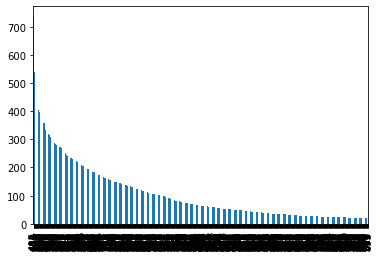

In [ ]:
ratings.user_id.value_counts().plot(kind='bar')    # In ratings dataset, we have 2 attributes: user_id and movie_id. user_id is no significant other than to count how
                                                   # many users have watched a particular movie.

                                                   # We will plot a bar graph which will depict the data of different users watching different kinds of movies.

In [ ]:
ratings.head()    # Finding ratings of all the movies.

,user_id,movie_id,ratings
0,196,242,3
1,186,302,3
2,22,377,1
3,244,51,2
4,166,346,1


Then we need to find the average rating of all the movies and store it into a dataframe 'movie_rating'.

And then we need to divide all the movies by their average ratings to know how many users have rated a particular movie. And then sort the data in ascending order of all the respective movie id(s).

Now we need to check how many movies are watched by how many users.
Because the situation is, in the movie_rating dataframe, we're unable to figure out that which movie is watched by how many users. 

Suppose 20 users have watched a particular movie, and each user has given a rating of 5 to that movie, so the average rating of that movie would be a 5. 

Now suppose there is another movie which has been watched by 50-100 users, and all the users have given different different ratings to that movie, and the average rating of that movie comes out to be a 3.5.

And now we're comparing both these movies with each other and decide that yes, former movie is the better than the latter one. So this kind of comaprison between both the movies would be unfair.

Therefore, we will have to divide the movie ratings by their average ratings to find how many users have given different ratings to that particular movie.

In [ ]:
movie_rating = ratings.groupby('movie_id').agg({'ratings': 'mean', 'user_id':'count'})    # agg() is used to find the average rating of all the movies here.
                                                                                          # We are applying the mean function over the ratings.


In [ ]:
movie_rating.rename({'ratings': 'avg_rating', 'user_id':'count'}, axis=1, inplace=True)

In [ ]:
movie_rating.head()

,avg_rating,count
movie_id,,
1,3.878319,452
2,3.206107,131
3,3.033333,90
4,3.550239,209
5,3.302326,86


The above O/P tells that first movie is watched by 452 users, second movie is watched by 131 users, and so on...

Now we need to normalize the average rating by calculating the popularity of all the movies. And since the difference between the 'count' attribute values is too large, we need to scale our dataset by applying Min-Max Scaling to keep the popularity scores of all the movies in a range of (0-1).

### **Calculating Popularity Score & Min-Max Scaling:**

Suppose there are total 1682 users and if a movie is watched by all the 1682 users, then that movie would be called as the most popular movie. So the popularity of this movie would be 1682/1682 = 1.

Now suppose if a movie is watched by only 1 user out of all the 1682 users, then the popularity of this movie would be calculated as 1/1682, which would come out as 0.000 something.

So we would use an attribute called 'count' as a scale to find the popularity of a particular movie. Since the count values are very big, i.e. the scale is big, this is why I used the concept of Min-Max Scaling to normalize everything.

$$  \text {Min Max Scaling} = \frac {X_i - min(X)} {max(X) - min(X)} $$

where,

**X_i:** X_i value of the transpose of a dataset

**min(X):** Minimum rating of a movie

**max(X):** Maximum rating of a movie

In [ ]:
x = [ 40, 60, 30, 10, 90, 100 ]                                  # 40 users have rated the first movie, 60 users have rated the second movie, and so on...
                                                                 # The last movie is the most popular one here, since it's been watched by 100 users.
                                                                 # The least popular movie here, is the one which is watched by merely 10 users.
#   [ 30, 50,  20, 0, 80, 90 ] by applying X_i - min(X)

y = [ round((xi-min(x)) / (max(x) - min(x)), 2) for xi in x ]    # Converting the result by applying round() up to 2 decimal places
print(x)
print(y)

[40, 60, 30, 10, 90, 100]
[0.33, 0.56, 0.22, 0.0, 0.89, 1.0]


The above O/P tells that the first movie is watched by 33% users, second movie is watched by 56% of users, and so on...

Also, the 4th movie is watched only by 1 user.

In [ ]:
1682 / 1682

1.0

In [ ]:
1 / 1682

0.0005945303210463733

In [ ]:
movie_rating['count'].max()    # Finding the most popular movie    
                               # Accessing the 'count' column and then finding the maximum value of 'count' in the 'count' column


583

So the above O/P tells that the most popular movie is watched by 583 users. So its popularity score should be a 1.

In [ ]:
movie_rating['count'].min()    # Finding the least popular movie

1

The above O/P tells that the least popular movie is watched by just 1 user.

In [ ]:
movie_rating['count'].mean()    # Finding the average no. of users who watch a particular movie

59.45303210463734

The above O/P tells that a particular movie is watched by at least 59 users.

Now we need to find the average no. of people who watch a movie and plot a histogram for it, for data visualization.

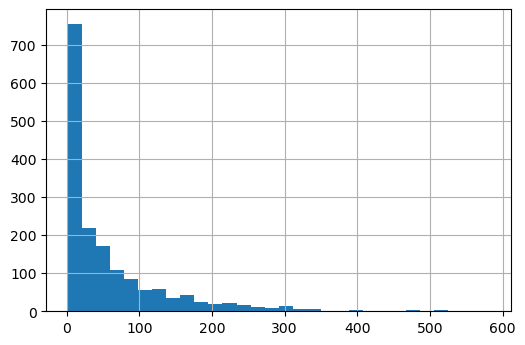

In [ ]:
plt.figure(dpi=100)
movie_rating['count'].hist(bins=30)
plt.show()

The above plot tells us that our data is right-skewed because maximum no. of bins are lying in the range of (0-50) movies on the left hand side.

X axis shows the no. of movies.

Y axis shows the no. of users.

In [ ]:
movie_rating['count'].quantile(q=[0.25, 0.5, 0.75])    # Finding the deviation in 'movie_rating' dataframe to know what percentage of people have given what average
                                                       # ratings to all the movies

0.25     6.0
0.50    27.0
0.75    80.0
Name: count, dtype: float64

**NOTE:** 'count' is the no. of people who have watched some percentage of movies and rated it.

Now, to normalize the 'count' column in 'movie_rating' dataframe, we need to find the minimum and maximum rating inside the 'count' column.

Then we need to create a new column named 'popularity' in which we need to store the 'count' column of movie_rating. And on 'count' column, we're supposed to apply a lambda function which will give us a value v. This lambda function is the same Min-Max Scaling function for calculating the popularity scores of all the movies.

In [ ]:
# Normalizing the 'count' column

mi = movie_rating['count'].min()                                                                # Finding the minimum value of 'count' column
mx = movie_rating['count'].max()                                                                # Finding the maximum value of 'count' column

movie_rating['popularity'] = movie_rating['count'].apply(lambda v: round((v-mi)/(mx-mi), 2))    # Creating a new column 'popularity' with the 'count' column
                                                                                                # Applying lambda function (Min-Max Scaling) on the 'count' column

Now since we have the popularity scores, the 'count' column is of no use to us anymore, so we are required to drop it, because the data in it will come out to be right-skewed, so the gap between the values would be too large. Hence we are required to scale it.

In [ ]:
movie_rating.drop('count', axis=1, inplace=True)

In [ ]:
movie_rating[movie_rating['popularity'] == 1].index.values[0]    # Finding the index (movie_id) of the most popular movie

50

In [ ]:
movie_rating.head()

,avg_rating,popularity
movie_id,,
1,3.878319,0.77
2,3.206107,0.22
3,3.033333,0.15
4,3.550239,0.36
5,3.302326,0.15


In [ ]:
movies.head()

,Action,Adventure,Animation,Children's,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
movie id,,,,,,,,,,,,,,,,,,
1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0
2,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
4,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0


Now we are required to check if the dataframes 'movies' and 'movie-rating' are having any missing data. We need to handle the missing data values if found any.

In [ ]:
movies.isna().sum()

Action         0
Adventure      0
Animation      0
Children's     0
Comedy         0
Crime          0
Documentary    0
Drama          0
Fantasy        0
Film-Noir      0
Horror         0
Musical        0
Mystery        0
Romance        0
Sci-Fi         0
Thriller       0
War            0
Western        0
dtype: int64

In [ ]:
movie_rating.isna().sum()

avg_rating    0
popularity    0
dtype: int64

To finally create the Movie Recommendation Model, we are required to merge both the pandas dataframes 'movies' and 'movie_rating' into a single dataframe named 'X', on the basis of index. And then we need to perform an inner join.

In [ ]:
X = pd.merge(movies, movie_rating, left_index=True, right_index=True)

Now we need to verify whether the merging has been done correctly or not.

In [ ]:
X.head()

,Action,Adventure,Animation,Children's,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,avg_rating,popularity
movie id,,,,,,,,,,,,,,,,,,,,
1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,3.878319,0.77
2,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,3.206107,0.22
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,3.033333,0.15
4,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,3.550239,0.36
5,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,3.302326,0.15


## **INSERTING DATA WITHIN CLUSTERS**

In [ ]:
# new_movie -> id, genres, avg_rating, popularity

Now we are supposed to find the titles of 50 most popular movies.

In [ ]:
ix_50 = movie_rating.sort_values('popularity', ascending=False)[:50].index    # Sorting movies in the descending order on the basis of popularity scores
                                                                              # And finding indices of top 50 movies

movie_title.loc[ix_50].head(20)                                               # Finding top 20 movies in ix_50

,movie title
movie_id,
50,Star Wars (1977)
100,Fargo (1996)
181,Return of the Jedi (1983)
258,Contact (1997)
294,Liar Liar (1997)
286,"English Patient, The (1996)"
288,Scream (1996)
1,Toy Story (1995)
300,Air Force One (1997)


Now we need to find the average rating and the popularity score of the most popular movie at index location 50 in movie_rating dataframe.

In [ ]:
movie_rating.loc[50]

avg_rating    4.358491
popularity    1.000000
Name: 50, dtype: float64

In [ ]:
star_wars = X.loc[50]

In [ ]:
star_wars

Action         1.000000
Adventure      1.000000
Animation      0.000000
Children's     0.000000
Comedy         0.000000
Crime          0.000000
Documentary    0.000000
Drama          0.000000
Fantasy        0.000000
Film-Noir      0.000000
Horror         0.000000
Musical        0.000000
Mystery        0.000000
Romance        1.000000
Sci-Fi         1.000000
Thriller       0.000000
War            1.000000
Western        0.000000
avg_rating     4.358491
popularity     1.000000
Name: 50, dtype: float64

Now we are supposed to find similar movies to the movie 'Star Wars' according to the features. Here our features are: genres, avg_rating, and popularity scores.

Now, two movies are said to be similar when the distance between them would be the least. So here we will find the distance between the different genres and the distance between the average rating and popularity score of a movie.

So we will use two different formulas for distance calculation since here we have vectors.

Since Euclidean Distance formula is applicable to find distance between two real values, and not between two vector values, so here we will use the Cosine Distance formula.

In [ ]:
v1 = [ 0, 1, 0, 1, 0]
v2 = [ 1, 0, 1, 1, 0]

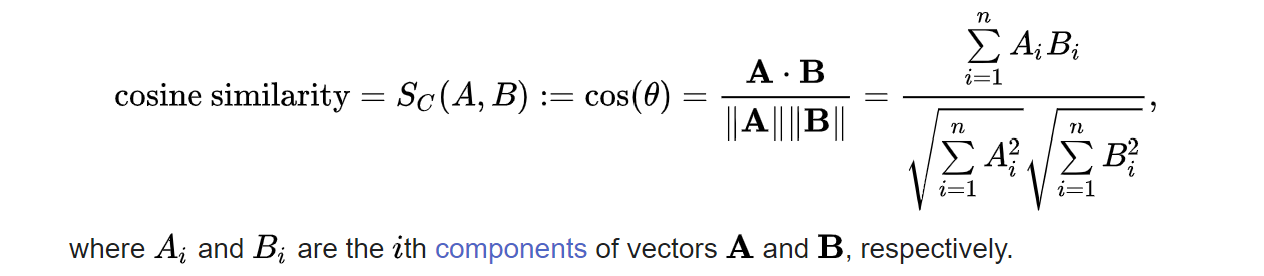

Then we are required to import SciPy library to use distance functions like euclidean() and cosine() to find the distances between two movies. Hence to find the least distance between two movies to find similar movies and recommend it accordingly.

In [ ]:
from scipy.spatial.distance import cosine, euclidean    # SciPy is a Python library that is useful in solving many mathematical equations and algorithms. It is 
                                                        # designed on the top of NumPy library that gives more extension of finding scientific mathematical formulae
                                                        # like matrix computation, etc.


In [ ]:
v1 = np.array([3.2, 0.5])    # Finding distance between the movie ratings
v2 = np.array([3.2, 0.5])

euclidean(v1, v2)

0.0

In [ ]:
v1 = np.array([ 0, 1, 0, 1, 0])    # Converting vector into array
v2 = np.array([ 1, 0, 1, 0, 1])    # Finding distance between the genres
print(euclidean(v1, v2))
cosine(v1, v2)

2.23606797749979


1.0

In [ ]:
v1 = np.array([ 0, 1, 0, 1, 0])
v2 = np.array([ 0, 1, 0, 1, 0])
print(euclidean(v1, v2))
cosine(v1, v2)

0.0


0.0

In [ ]:
X.head()    # Checking out the data in the merged dataframe 'X'

,Action,Adventure,Animation,Children's,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,avg_rating,popularity
movie id,,,,,,,,,,,,,,,,,,,,
1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,3.878319,0.77
2,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,3.206107,0.22
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,3.033333,0.15
4,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,3.550239,0.36
5,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,3.302326,0.15


In [ ]:
def distance(v1, v2):
    return euclidean(v1, v2)

## **GENERATING RECOMMENDATIONS**

### **KNN ALGORITHM**

The 'K' in the KNN Algorithm is the no. of nearest neighbors to a new unknown variable, i.e. a new movie inputted by the user, that has to be predicted or classified. So this KNN Algorithm would now use the data, as in, it would use the attributes of the movie inputted by the user, and then classify new data points, i.e., it would find new similar movies based on the similarity measures.

And since two movies are said to be similar only when the distance between them is the least, I have used some specific distance functions like Euclidean Distance and Cosine Distance to find similar movies in my Movie Recommendation Model.

Now we need to define a function named 'similarMovies()' to find similar movies by implementing KNN Algorithm in which we will pass some properties of some movie, to find K similar movies and recommend it accordingly.

In [ ]:
def similarMovies(mid, k=5):                         # Passing a new movie (movie_id) and passing k=5 since we want 5 similar movies to the new movie which is passed.
    X_new = X.loc[mid].values                        # loc[mid] means location of movie ID(s)
    result = []
    for ix, each_movie in zip(X.index, X.values):    # ix is used for index
        d = distance(X_new, each_movie)              # Finding the distance between the new movie which is passed and each movie in our dataset.
        result.append( (d, ix) )
    result.sort()
    
    movie_ids = [ ix for d, ix in result[:k] ]
    return movie_title.loc[movie_ids]                # Printing the names of movies
        

In [ ]:
similarMovies(50, k=10)    # Finding similar movies to 'Star Wars'; and mid of Star Wars is 50

,movie title
movie id,
50,Star Wars (1977)
181,Return of the Jedi (1983)
172,"Empire Strikes Back, The (1980)"
498,"African Queen, The (1951)"
222,Star Trek: First Contact (1996)
228,Star Trek: The Wrath of Khan (1982)
271,Starship Troopers (1997)
82,Jurassic Park (1993)
121,Independence Day (ID4) (1996)


In [ ]:
similarMovies(313, k=10)    # Finding similar movies to the movie 'Titanic'

,movie title
movie id,
313,Titanic (1997)
207,Cyrano de Bergerac (1990)
1483,"Man in the Iron Mask, The (1998)"
197,"Graduate, The (1967)"
275,Sense and Sensibility (1995)
14,"Postino, Il (1994)"
213,"Room with a View, A (1986)"
268,Chasing Amy (1997)
246,Chasing Amy (1997)


In [ ]:
similarMovies(127, k=10)    # Finding similar movies to the movie 'Godfather'.

,movie title
movie id,
127,"Godfather, The (1972)"
187,"Godfather: Part II, The (1974)"
56,Pulp Fiction (1994)
806,Menace II Society (1993)
182,GoodFellas (1990)
293,Donnie Brasco (1997)
504,Bonnie and Clyde (1967)
1194,Once Were Warriors (1994)
1191,"Letter From Death Row, A (1998)"
